# Сингулярный спектральный анализ (SSA) сигнала акселерометра

**Задача.** Разложить сигнал акселерометра смартфона при беге на компоненты методом SSA (тренд, периодичность, шум) и исследовать, как длина окна L влияет на разделимость компонент.

**Данные.** MotionSense (лицензия MIT, [github.com/mmalekzadeh/motion-sense](https://github.com/mmalekzadeh/motion-sense)): `A_DeviceMotion_data/jog_9/sub_21.csv` — бег (jogging), участник 21, частота 50 Гц. Копия файла лежит в `../data/motionsense_jog_9_sub_21.csv`.

**План.**
1. Модуль вектора ускорения `userAcceleration`, участок 10–25 с (751 отсчёт).
2. Реализация SSA: траекторная матрица → SVD → элементарные матрицы → диагональное усреднение; w-корреляционная матрица.
3. Сравнение L = 50, 150, 300: компоненты, w-корреляции, реконструкция по первым 12 компонентам.
4. Сингулярный спектр для L = 300.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [2]:
df = pd.read_csv('../data/motionsense_jog_9_sub_21.csv')

# Вычисляем модуль вектора ускорения (евклидова норма)
df['accel_mag'] = np.sqrt(df['userAcceleration.x']**2 + df['userAcceleration.y']**2 + df['userAcceleration.z']**2)

# Преобразуем индекс в секунды
df.index = df.index / 50.0
df.index.name = 'Time (s)'

# Берем 15-секундный участок (750 отсчетов), чтобы можно было использовать окно L=300
start_time, end_time = 10, 25
ts = df.loc[start_time:end_time]['accel_mag']
N = len(ts)
print(f"Длина выбранного ряда: {N} отсчетов ({(end_time - start_time)} секунд)")

Длина выбранного ряда: 751 отсчетов (15 секунд)


In [3]:
# Оценка доминирующего периода сигнала по спектру (FFT) — для выбора длины окна L
x = ts.values - ts.values.mean()
freqs = np.fft.rfftfreq(len(x), d=1 / 50.0)
power = np.abs(np.fft.rfft(x)) ** 2
mask = freqs > 0.5   # отбрасываем очень низкие частоты (медленный дрейф)
top = np.argsort(power[mask])[::-1][:3]
for f in freqs[mask][top]:
    print(f"Частота {f:.2f} Гц -> период {1 / f:.2f} с ({50 / f:.0f} отсчётов)")

Частота 2.73 Гц -> период 0.37 с (18 отсчётов)
Частота 2.66 Гц -> период 0.38 с (19 отсчётов)
Частота 6.66 Гц -> период 0.15 с (8 отсчётов)


In [4]:
# Реализация SSA (основана на вспомогательном коде из учебных материалов курса, переработана)
# Реализация класса SSA
class SSA:
    def __init__(self, tseries, L):
        self.orig_TS = tseries  # Сохраняем оригинальный Series
        self.ts = np.array(tseries)
        self.N = len(self.ts)
        if not 2 <= L <= self.N / 2:
            raise ValueError(f"Длина окна L должна удовлетворять условию: 2 <= L <= N/2 ({self.N/2})")
        self.L = L
        self.K = self.N - self.L + 1

        # Шаг 1: Построение матрицы траекторий
        self.X = np.column_stack([self.ts[i:i+self.L] for i in range(self.K)])

        # Шаг 2: Сингулярное разложение (SVD)
        self.U, self.Sigma, self.Vt = np.linalg.svd(self.X, full_matrices=False)
        self.V = self.Vt.T

        # Шаг 3: Элементарные матрицы
        self.d = min(self.L, self.K)
        self.X_elem = [self.Sigma[i] * np.outer(self.U[:, i], self.V[:, i]) for i in range(self.d)]

        # Шаг 4: Диагональное усреднение для получения компонент временного ряда
        self.ts_comps = np.zeros((self.N, self.d))
        for i in range(self.d):
            self.ts_comps[:, i] = self._diagonal_averaging(self.X_elem[i])

    def _diagonal_averaging(self, X_elem):
        L, K = X_elem.shape
        N = L + K - 1
        ts_comp = np.zeros(N)
        for k in range(N):
            start_row = max(0, k - K + 1)
            end_row = min(L - 1, k)
            num_elements = end_row - start_row + 1
            # Суммирование по антидиагонали
            diag_sum = sum(X_elem[i, k - i] for i in range(start_row, end_row + 1))
            ts_comp[k] = diag_sum / num_elements
        return ts_comp

    def reconstruct(self, indices):
        if isinstance(indices, int):
            indices = [indices]
        return pd.Series(self.ts_comps[:, indices].sum(axis=1), index=self.orig_TS.index)

    def wcorr(self):
        # Расчет w-корреляционной матрицы
        w = np.array(list(range(1, self.L + 1)) + [self.L] * (self.K - self.L - 1) + list(range(self.L, 0, -1)))
        F_wnorms = np.array([np.sqrt(np.sum(w * self.ts_comps[:, i]**2)) for i in range(self.d)])
        W_corr = np.identity(self.d)
        for i in range(self.d):
            for j in range(i + 1, self.d):
                w_inner = np.sum(w * self.ts_comps[:, i] * self.ts_comps[:, j])
                W_corr[i, j] = w_inner / (F_wnorms[i] * F_wnorms[j])
                W_corr[j, i] = W_corr[i, j]
        return W_corr

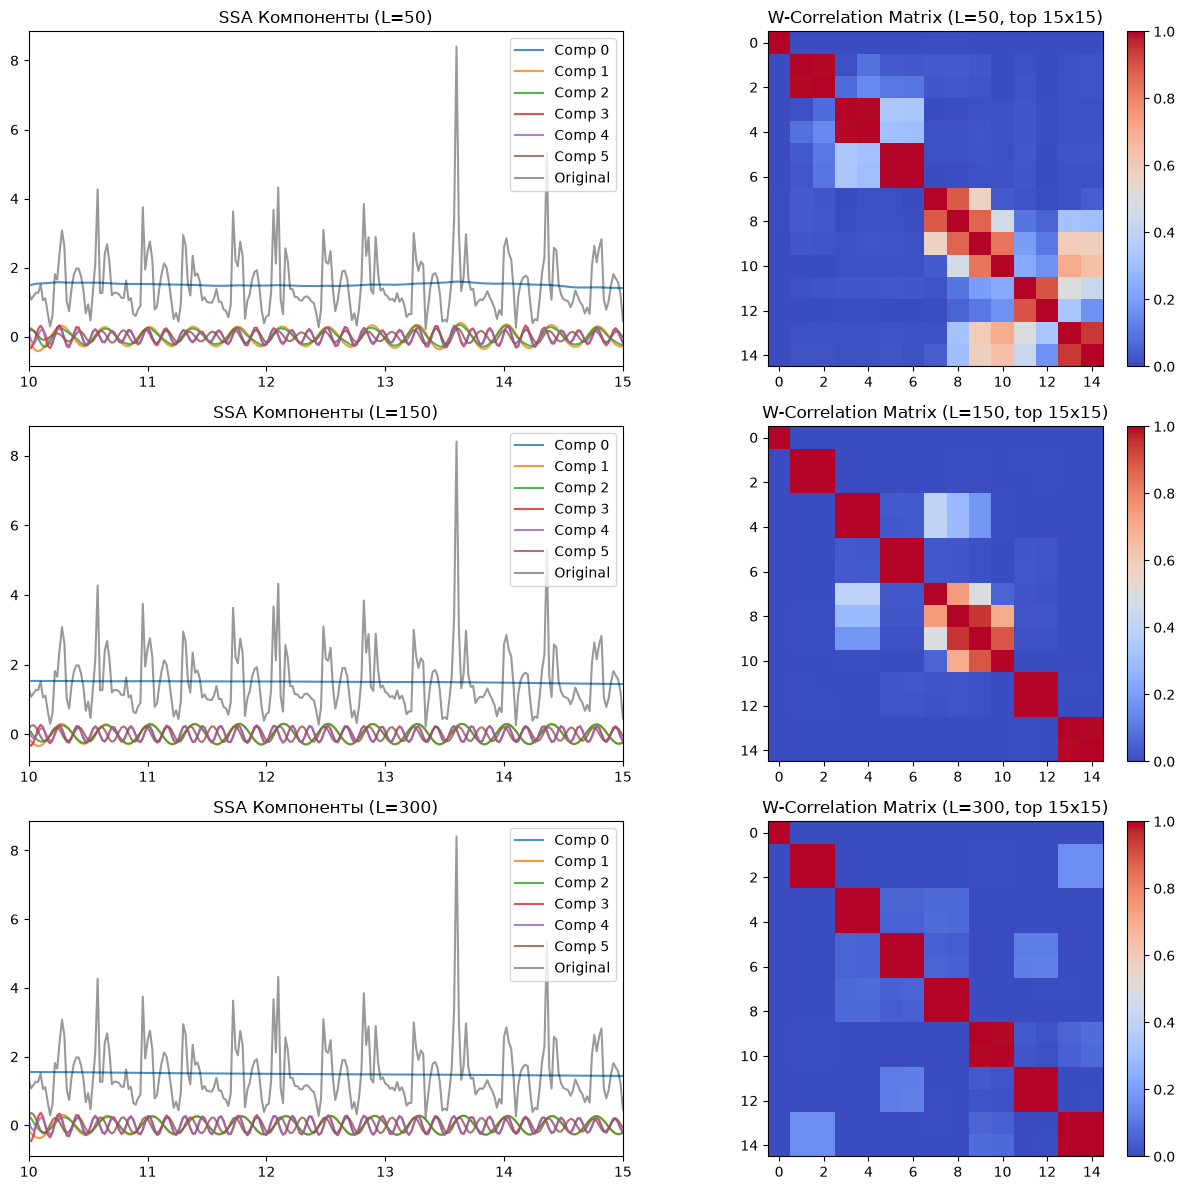

In [5]:
# Проведение SSA для 3-х разных длин окон L=50 (~1 сек), L=150 (~3 сек), L=300 (~6 сек)
window_lengths = [50, 150, 300]

fig, axes = plt.subplots(len(window_lengths), 2, figsize=(12, 4 * len(window_lengths)))

for idx, L in enumerate(window_lengths):
    ssa = SSA(ts, L)

    # График 1: Первые 6 элементарных компонент
    for i in range(min(6, ssa.d)):
        axes[idx, 0].plot(ssa.reconstruct(i), label=f'Comp {i}', alpha=0.8)
    axes[idx, 0].plot(ts, label='Original', alpha=0.4, color='black')
    axes[idx, 0].set_title(f'SSA Компоненты (L={L})')
    axes[idx, 0].legend(loc='upper right')
    axes[idx, 0].set_xlim(10, 15) # Зум для наглядности

    # График 2: W-корреляционная матрица (показываем первые 15x15 для читаемости)
    wcorr = ssa.wcorr()
    limit = min(15, ssa.d)
    im = axes[idx, 1].imshow(np.abs(wcorr[:limit, :limit]), cmap='coolwarm', vmin=0, vmax=1)
    axes[idx, 1].set_title(f'W-Correlation Matrix (L={L}, top {limit}x{limit})')
    plt.colorbar(im, ax=axes[idx, 1], fraction=0.046, pad=0.04)

plt.tight_layout()
plt.show()

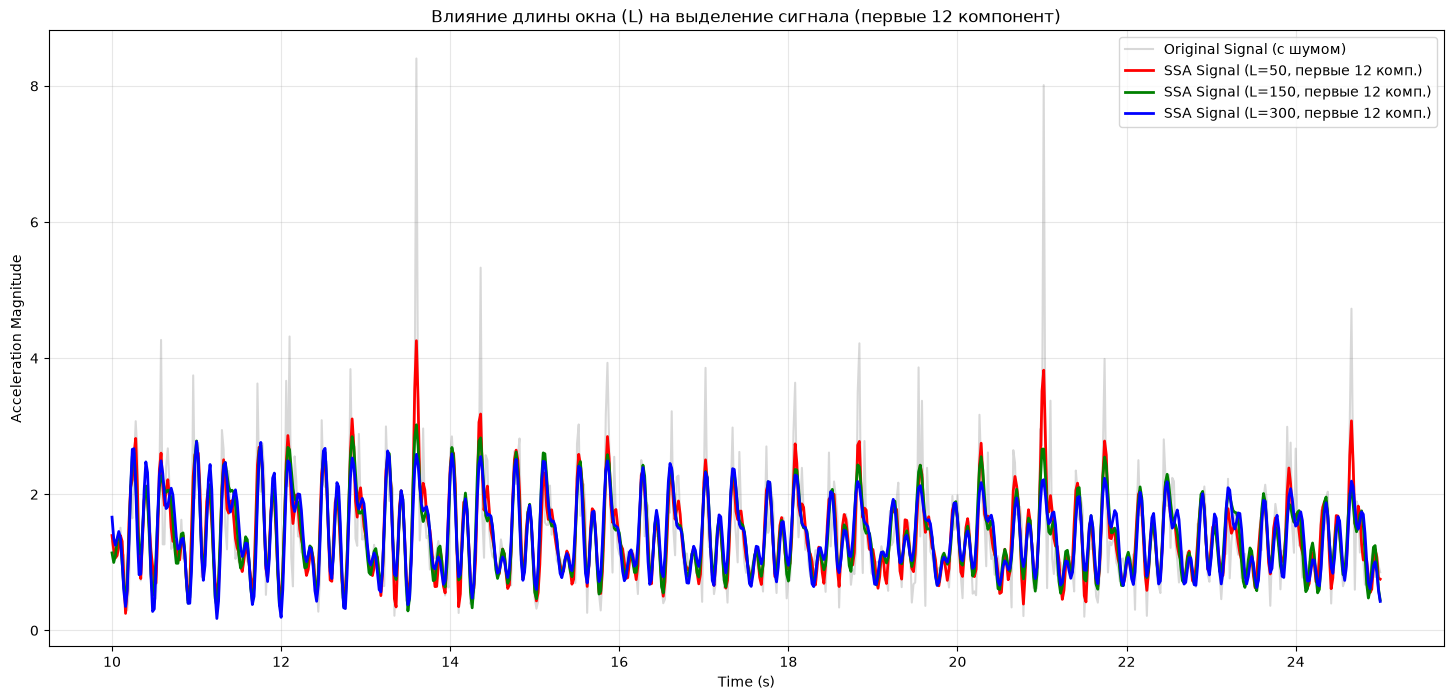

In [6]:
# Сравнение "Сигнала" (Тренд + Периодичность) при фиксированном числе компонент
plt.figure(figsize=(18, 8))
plt.plot(ts, label='Original Signal (с шумом)', alpha=0.3, color='gray')

colors = ['red', 'green', 'blue']
num_components = 12  # Берем фиксированное число ведущих компонент (отбрасываем "хвост" из шумовых компонент)

for idx, L in enumerate(window_lengths):
    ssa = SSA(ts, L)
    # Берем срез первых компонент
    recon = ssa.reconstruct(slice(0, num_components))
    plt.plot(recon, label=f'SSA Signal (L={L}, первые {num_components} комп.)',
             color=colors[idx], linewidth=2)

plt.title('Влияние длины окна (L) на выделение сигнала (первые 12 компонент)')
plt.xlabel('Time (s)')
plt.ylabel('Acceleration Magnitude')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

In [7]:
# Функция для расчета собственных значений траекторной матрицы
def get_singular_values(ssa_obj):
    # Траекторная матрица X имеет размер L x K
    # Сингулярные числа sigma, собственные числа lambda = sigma^2
    L, K = ssa_obj.L, ssa_obj.K
    X = np.zeros((L, K))
    for i in range(L):
        X[i, :] = ssa_obj.ts[i : i + K]

    # SVD разложение
    U, sigma, Vt = np.linalg.svd(X, full_matrices=False)
    lambdas = sigma**2
    return lambdas

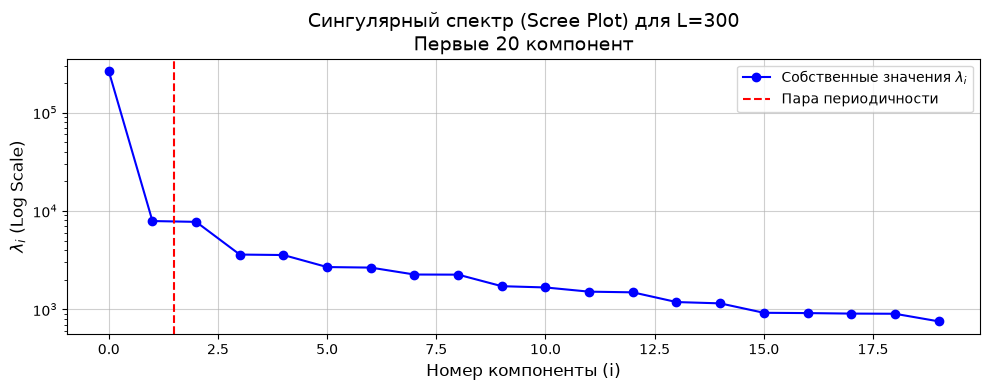

In [8]:
# Построение графика сингулярного спектра для L=300
ssa_opt = SSA(ts, 300)
lambdas = get_singular_values(ssa_opt)

plt.figure(figsize=(10, 4))
# График в полулогарифмической шкале, чтобы было видно "хвост" шума
plt.plot(lambdas[:20], marker='o', linestyle='-', color='b', label=r'Собственные значения $\lambda_i$')
plt.title('Сингулярный спектр (Scree Plot) для L=300\nПервые 20 компонент', fontsize=14)
plt.xlabel('Номер компоненты (i)', fontsize=12)
plt.ylabel(r'$\lambda_i$ (Log Scale)', fontsize=12)
plt.yscale('log')
plt.grid(True, alpha=0.6)
plt.axvline(x=1.5, color='r', linestyle='--', label='Пара периодичности')
plt.legend()
plt.tight_layout()
plt.show()

In [9]:
# Количественная проверка группировки для L=300:
# вклад каждой компоненты в сумму собственных значений и её доминирующий период
contrib = ssa_opt.Sigma ** 2 / np.sum(ssa_opt.Sigma ** 2)
freqs_c = np.fft.rfftfreq(ssa_opt.N, d=1 / 50.0)
wc = ssa_opt.wcorr()
print(f"{'Комп.':>5} | {'вклад, %':>8} | {'период, с':>9} | w-corr со следующей")
for i in range(13):
    comp = ssa_opt.ts_comps[:, i]
    spec = np.abs(np.fft.rfft(comp - comp.mean()))
    f = freqs_c[1:][np.argmax(spec[1:])]
    period = '—' if i == 0 else f'{1 / f:.2f}'
    print(f"{i:>5} | {100 * contrib[i]:>8.2f} | {period:>9} | {abs(wc[i, i + 1]):.2f}")
print(f"Суммарный вклад первых 12 компонент: {100 * contrib[:12].sum():.1f}%")

Комп. | вклад, % | период, с | w-corr со следующей
    0 |    75.02 |         — | 0.00
    1 |     2.25 |      0.37 | 1.00
    2 |     2.20 |      0.37 | 0.00
    3 |     1.02 |      0.15 | 1.00
    4 |     1.01 |      0.15 | 0.05
    5 |     0.76 |      0.19 | 1.00
    6 |     0.76 |      0.19 | 0.06
    7 |     0.64 |      0.15 | 1.00
    8 |     0.64 |      0.15 | 0.00
    9 |     0.49 |      0.75 | 1.00
   10 |     0.47 |      0.75 | 0.02
   11 |     0.43 |      0.18 | 1.00
   12 |     0.42 |      0.18 | 0.00
Суммарный вклад первых 12 компонент: 85.7%


Комментарий: в сингулярном спектре выделяется компонента 0 (медленно меняющийся уровень, 75% суммы собственных значений — сигнал не центрирован) и пары с почти равными собственными значениями (1–2, 3–4, 5–6, 7–8, 9–10, 11–12) — так в SSA проявляются гармоники. Первые 12 компонент дают 85.7% суммы собственных значений; при этом граница «12 компонент» разрывает пару (11, 12), поэтому для реконструкции корректнее брать 13 компонент (0–12).

## Итоговые выводы: влияние длины окна $L$ на результаты SSA

Проведён сингулярный спектральный анализ сигнала акселерометра при беге (модуль ускорения, 15 с, 751 отсчёт при 50 Гц) с целью выделить медленный уровень, периодические составляющие и шум. Ключевой гиперпараметр метода — длина окна $L$; сравнивались $L = 50, 150, 300$ (1, 3 и 6 с).

### 1. Период сигнала
По спектру (FFT) доминирующий период — **0.37 с** (2.73 Гц, около 18 отсчётов) — это период шага. В компонентах SSA также видны период **0.75 с** (двойной шаг — вероятно, асимметрия левой и правой ноги) и гармоники 0.15–0.19 с, описывающие форму ударного импульса.

*Исправление по сравнению с первой версией работы:* там период цикла бега был оценён в 2.5–3.5 с; расчёт показывает, что он на порядок меньше. Поэтому все три окна, включая $L=50$, покрывают несколько периодов шага, и разница между ними объясняется не «захватом полного цикла», а разделимостью компонент.

### 2. Диагностика через w-корреляционную матрицу
W-корреляционная матрица — основной инструмент этапа группировки.
* **$L=50$:** ведущие пары (1–2, 3–4, 5–6) в основном разделяются (между 3–4 и 5–6 w-корреляция около 0.3–0.4), но компоненты 7–14 заметно коррелируют между собой (w-корреляции до 0.6–0.9) — гармоники смешиваются.
* **$L=150$:** смешение сохраняется в группе компонент 7–10 и частично между 3–4 и 7–9.
* **$L=300$:** матрица имеет чёткую блочно-диагональную структуру из блоков 2×2 (пары гармоник), внедиагональные w-корреляции не выше ~0.3. Внутри каждой пары w-корреляция ≈ 1.0, между соседними парами — 0.00–0.06, то есть компоненты хорошо разделимы.

### 3. Интерпретация компонент (L = 300)
* **Компонента 0:** медленно меняющийся средний уровень ускорения (аналог тренда).
* **Компоненты 1–2:** основная периодичность — шаг (0.37 с).
* **Компоненты 9–10:** двойной шаг (0.75 с).
* **Компоненты 3–8, 11–12:** высшие гармоники шага (0.15–0.19 с), форма импульса при ударе стопы.
* **Остальные компоненты:** шум — вибрации датчика и нерегулярности движения.

**Резюме.** Для периодических сигналов (шаг, сердечный ритм, вибрации) окно должно покрывать много периодов; рекомендация $L \le N/2$, по возможности кратное периоду. Из рассмотренных вариантов $L=300$ (около 16 периодов шага) даёт наилучшую разделимость компонент при умеренных вычислительных затратах. Выбор $L$ и группировки здесь сделан визуально; количественная проверка (например, ошибка реконструкции или устойчивость на других участниках) — следующий шаг.